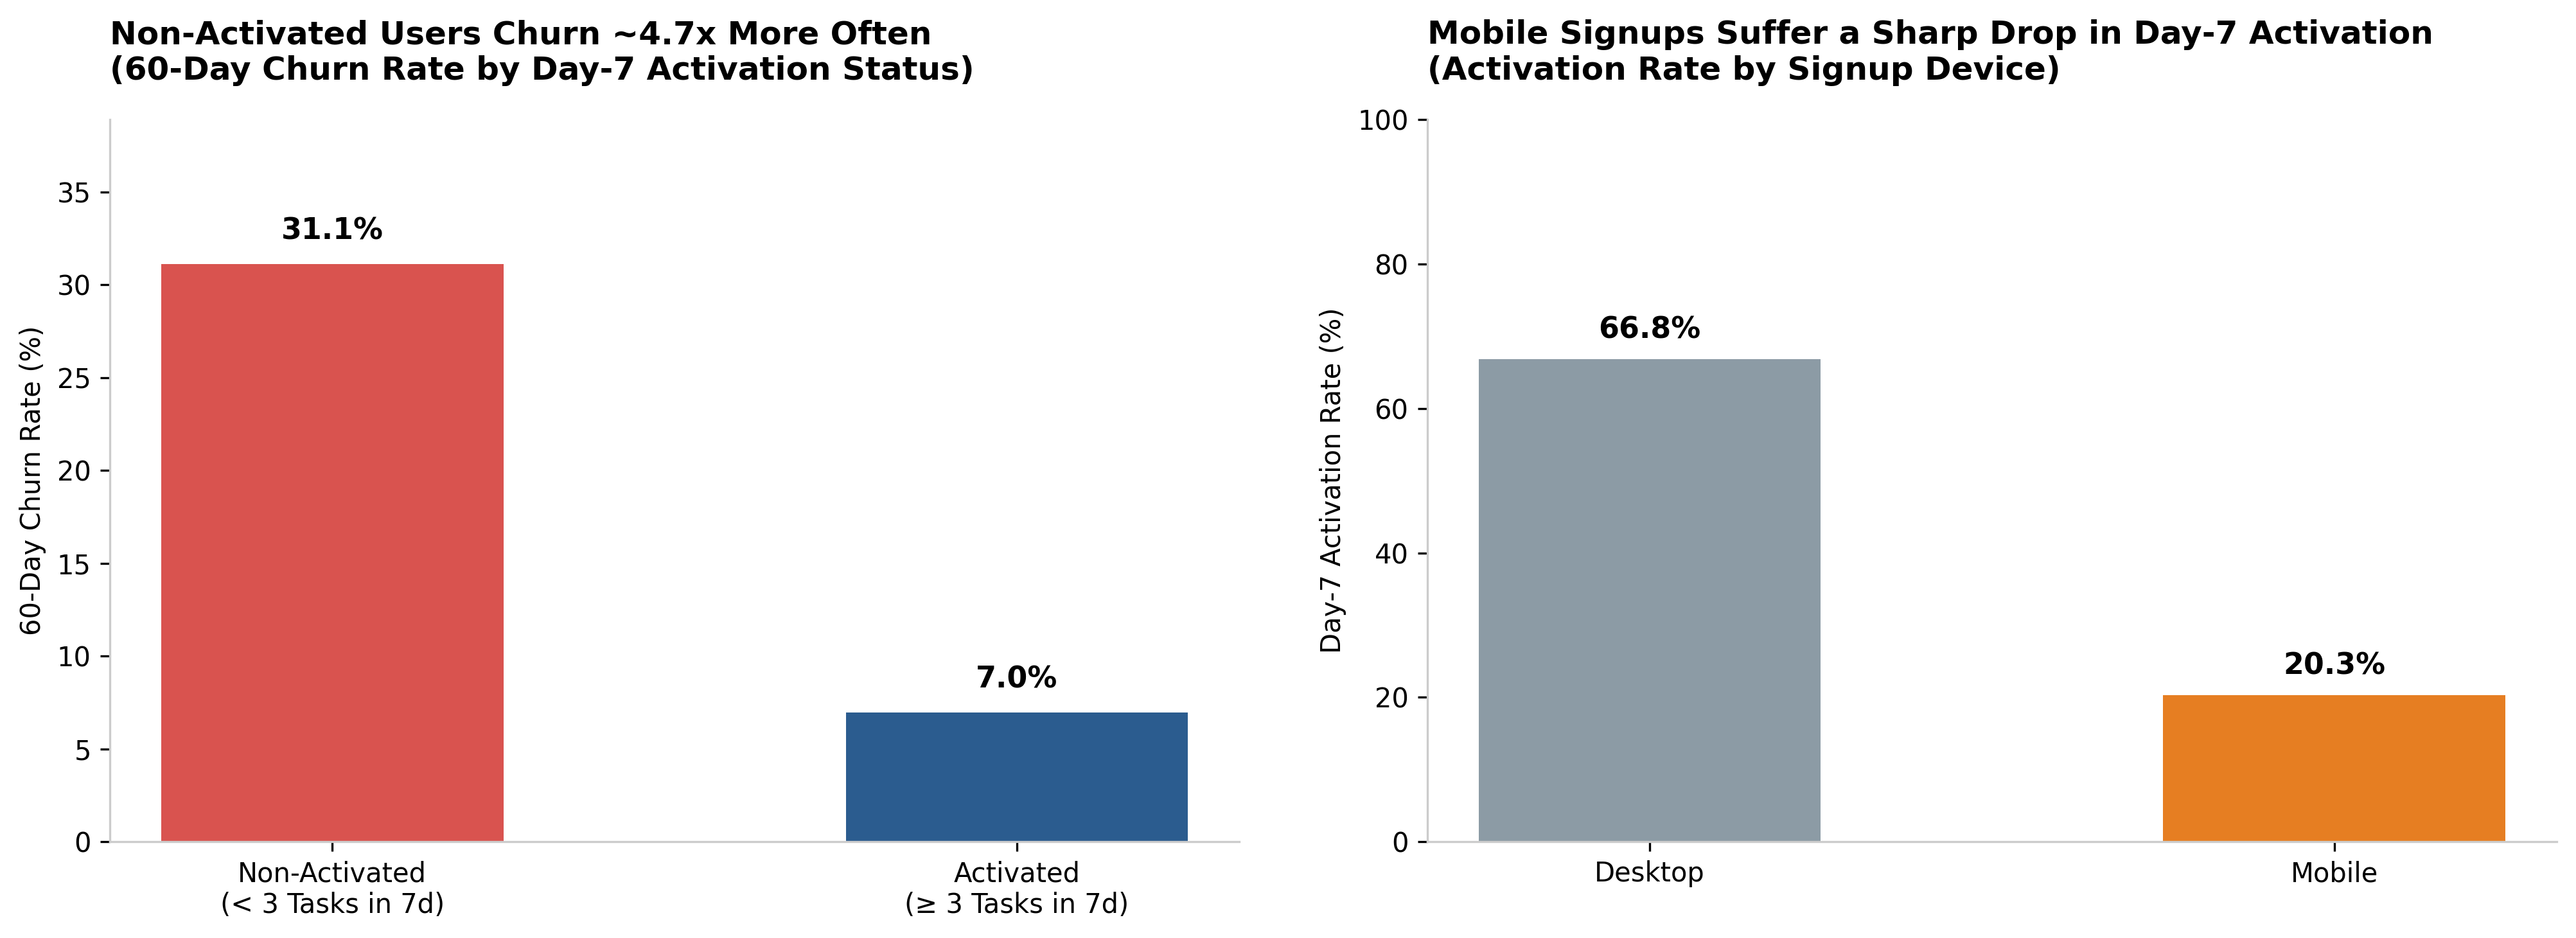

BERHASIL! Data dan Grafik sudah siap.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# 1. Membuat Data Simulasi 5.000 User
np.random.seed(42)
n_users = 5000
user_ids = [f"USR_{10000 + i}" for i in range(n_users)]
signup_dates = pd.to_datetime('2026-04-01') + pd.to_timedelta(np.random.randint(0, 180, n_users), unit='D')
devices = np.random.choice(['Desktop', 'Mobile'], size=n_users, p=[0.65, 0.35])
plans = np.random.choice(['Monthly', 'Annual'], size=n_users, p=[0.70, 0.30])

tasks_7d = [np.random.poisson(3.4) if dev == 'Desktop' else np.random.poisson(1.6) for dev in devices]
tasks_7d = np.array(tasks_7d)
is_activated = (tasks_7d >= 3).astype(int)

churn_prob = []
for act, plan in zip(is_activated, plans):
    base_prob = 0.08 if act == 1 else 0.38
    if plan == 'Annual':
        base_prob *= 0.4
    churn_prob.append(base_prob)

churned_60d = np.random.binomial(1, churn_prob)

df = pd.DataFrame({
    'user_id': user_ids,
    'signup_date': signup_dates,
    'cohort_month': signup_dates.to_period('M').astype(str),
    'device': devices,
    'plan_type': plans,
    'tasks_completed_7d': tasks_7d,
    'is_activated': is_activated,
    'churned_60d': churned_60d
})

# Simpan data ke file CSV
df.to_csv('streamflow_saas_churn.csv', index=False)

# 2. Membuat Gambar Grafik
plt.rcParams['font.sans-serif'] = 'Arial'
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)
fig.patch.set_facecolor('white')

act_summary = df.groupby('is_activated')['churned_60d'].mean() * 100
bars1 = axes[0].bar(['Non-Activated\n(< 3 Tasks in 7d)', 'Activated\n(≥ 3 Tasks in 7d)'], act_summary.values, color=['#D9534F', '#2B5C8F'], width=0.5)
axes[0].set_title('Non-Activated Users Churn ~4.7x More Often\n(60-Day Churn Rate by Day-7 Activation Status)', fontsize=12, fontweight='bold', loc='left', pad=15)
axes[0].set_ylabel('60-Day Churn Rate (%)')
axes[0].set_ylim(0, max(act_summary.values) * 1.25)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

dev_summary = df.groupby('device')['is_activated'].mean().reindex(['Desktop', 'Mobile']) * 100
bars2 = axes[1].bar(dev_summary.index, dev_summary.values, color=['#8C9BA5', '#E67E22'], width=0.5)
axes[1].set_title('Mobile Signups Suffer a Sharp Drop in Day-7 Activation\n(Activation Rate by Signup Device)', fontsize=12, fontweight='bold', loc='left', pad=15)
axes[1].set_ylabel('Day-7 Activation Rate (%)')
axes[1].set_ylim(0, 100)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 2, f'{yval:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout(pad=3.0)
plt.savefig('portfolio_charts_streamflow.png', dpi=300)
plt.show()
print("BERHASIL! Data dan Grafik sudah siap.")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')